MAGALY BENAVIDES SANTIAGO

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Actividad

El objetivo de esta actividad es comprobar que se comprendieron las decisiones
metodológicas y los resultados principales del Notebook 03.

Las respuestas deben escribirse con sus propias palabras. Cuando se solicite un
cálculo o una gráfica, deberá incluirse el código utilizado y una breve interpretación
del resultado.

## Parte A. Comprensión conceptual

### 1. De registro XML a unidad analítica

Explica la diferencia entre:

- un registro crudo de medicamento; es tal cual como viene el dato original directo del archivo XMl sin tocarle ni limpiarle nada, con todo y sus posibles  repeticiones o desordenes
- una unidad analítica de medicamento; es el mismo dato pero ya limpio, filtrado y sin duplicados interos, listo para usarse en el analisis
- un `drug_key`; es la etiqueta o clave estandar que se le asigna al medicamento, buscado que se un ingrediente activo para agruparlo de forma uniforme
- un par medicamento--reacción: es la combinacion cruzada entre el medicamento sospechoso y la reaccion adversa que sufrio el paciente. 

¿Por qué no sería correcto interpretar cada registro XML de medicamento como una
exposición independiente? 
Porque a veces en un mismo reportes hay varios reportes que refieren exactamnete a la misma mediciona, es decir, escrita con otro nombre o repetida por error, si contaramos cada registro suelto como si fuera una exposicion unica, terminariamos inflando los numeros y contando doble las cosas 




### 2. Construcción de `drug_key`

Explica la regla utilizada para construir `drug_key`:

$$
\texttt{drug\_key}
=
\begin{cases}
\texttt{activesubstancename}, &
\text{si está disponible},\\
\texttt{medicinalproduct}, &
\text{en caso contrario}.
\end{cases}
$$

Contesta:

a) ¿Por qué se prefirió `activesubstancename` sobre `medicinalproduct`?  
Porque lo que nos interesa estudiar a fondo es el principio activo, la sustancia quimica real que genera el efecto in importa las distintas marcas comercisles con las que se venden en el mercado 

b) ¿Qué significa que `drug_key_source = PRODUCT_FALLBACK`?  
significa que en ese reporte en especifico no venia escrito el ingrediente activo, asi que tuvimos  que recurrir al usar el nombre comercial del producto tal y como venia anotado

c) ¿Por qué no se imputó automáticamente un ingrediente activo cuando éste no estaba
disponible?  
porque en el analisis de datos no debemos invertir ni adivinar informacion que no este en los documentos origianles, por eso usamos como respaldo product_fallaback que andar poniendo ingredientes al azar. 


### 3. Papel del medicamento

Describe el significado de los cuatro valores de `drugcharacterization` utilizados
en este notebook:

- 1 = `Suspect`; es el medicamento principal al que se le considera sospechoso, es decir, el que causa la reaccion adversa
- 2 = `Concomitant`; es el medicamento que  el paciente tambien tomaba al mismo tiempo pero que no son los principales sospechosos del problema
- 3 = `Interacting`; es el farmaco que se sospecha que interacuaron entre si para provocar el evento adverso
- 4 = `Drug not administered`: mediamentos que aparecen en el reporte pero que por alguna razon nunca llegaron a administrarse al paciente

Explica por qué la cohorte principal utiliza solamente

$$
\texttt{drugcharacterization}=1
$$  
Porque en farmacovigilancia el codigo 1 significa que el medicamento es el sospechoso principal de haber provocado el daño a la reaccion adversa 

y por qué no sería correcto considerar el código 2 como otro tipo de medicamento
sospechoso.  
Porque no seria correcto meter al codigo 2 (porque son medicamentos concomitantes, es decir el paciente tambien lo tomaba pero sin la sospecha  principal de causar el problema) como si fueran sospechosos porque eso mezclaria las cosas y arrunaria la punteria para detectar señales  reales de toxicidad de un farmaco en especifico

### 4. Repeticiones internas

En la extracción completa se obtuvieron:

- 11,898,964 registros crudos de medicamentos;
- 7,668,249 unidades analíticas de medicamentos;
- 8,383,257 registros crudos de reacciones;
- 8,273,008 unidades analíticas de reacciones.

Explica por qué la reducción es mucho mayor para medicamentos que para reacciones.  

¿Qué característica de la estructura XML de FAERS produce este comportamiento?  

La reduccion en los medicamentos es enorme porque en los reportes de faers es muy comun que una misma mediciona se escriba varias veces bajo diferenctes nombres comerciales, distintas presentaciones o con pequeñas variaciones de formato dentro del mismo expediente XML.  
En cambio las reacciones adversas casi no sufren cambios porque se codifican de manera estricta y directa utilizando un termino medico unificado por lo que rara vez se repite de forma innecesaria dentro del mismo reporte



### 5. Producto cartesiano dentro de un reporte

Si un reporte contiene $D_i$ medicamentos elegibles y $R_i$ reacciones, el número de
pares potenciales es

$$
P_i=D_iR_i.
$$

Explica qué representa este producto cartesiano.  
Representa todas las combinaciones posibles  que se pueden armar juntando cada medicamento elegible con cada una de las reacciones reportadas en ese mismo expediente, por ejemplo si un paciente tomo dos medicinas y tuvo 3 reacciones, entonces el producto cartesiano te arma 6 parejas distintas 

¿Por qué la existencia de un par medicamento--reacción dentro de un reporte **no**
significa que el medicamento haya causado la reacción?
Porque un reporte de farmacovigilancia solo junta los datos de lo que le paso a un paciente, pero que aparezcan juntos no comprueba automaticamente que la medicina haya sido la causante idrecta del sintoma. Para eso se necesita hacer despues el analisis estadistico u buscar señales  relaes ya que muchas veces se reportan medicamentos por precaucion o coincidencia. 

### 6. Versionado y `release_view`

Explica para qué se utilizó `release_view`.  
Se uso como filtro de control indispensable para asegurar que por cada trimestre, de cada expediente medico solo exista una unica version oficial activa evitando dupliaciones por actualizaciones del caso

En particular, describe qué problema se habría producido con el caso

```text
safetyreportid = 26012757
```  
Se habrian duplicado los datos de ese paciente, lo que habia  inflado los numeros artificialmente agregando 1100 pares de mas que en realidad correspondian a un mismo reporte actualizado

si se hubieran conservado simultáneamente sus dos versiones dentro de 2026Q2.

¿Por qué esta corrección debía realizarse antes de construir los pares?  
Porque su nos ponemos a sacar los productos cartesianos con versiones repetidas, ese error de duplicidad se arrastaria en las multiplicaciones y alteraria por completo los totales de los pares y los calculos de las señales.

### 7. Dos escalas temporales

Explica la diferencia conceptual entre:

```text
qde_period
```  

Es el trimestre en el que se libero o publico oficialmente el lote de datos de FAERS donde se encontro el reporte

y

```text
analysis_quarter
```  
Es el trimestres real en el que la autoridad sanitaria recibio el reporte de manera fisica o digital (calculado a partir de lafecha de recepcion, receiptdate)

Indica cuál utilizarías principalmente para:

a) estudiar persistencia de señales entre liberaciones trimestrales;  
Y creo que utilizaria qde_period porque esta diseñada justamnete para rastrear como se comportan lo datos trimestre a trimestre en las publicaiones oficiales

b) estudiar la distribución de reportes según su fecha de recepción.  
Aqui utilizaria analysis_quarter ya que refleja el tiempo cronologico real en el que ocurrieron y se recibieron las notificaciones

Finalmente, explica por qué es importante conservar ambas variables aunque en este
conjunto coincidan en aproximadamente el $99.99\%$ de las apariciones.  

Porque miden cosas distintas: una es cuando se actualizo el caso en el sietma y la oyra cuando llego el reporte original, aunque casi siempre coincidan, tener ambas es vital para detectar casos o ajustes de fechas sin perdeer el orden cronologico 

## 8. Reducción producida por la construcción de unidades analíticas

Carga el archivo

```text
derived/extraction_03/resumen_notebook03.csv
```

El archivo contiene dos columnas:

- `metric`: nombre del indicador;
- `value`: valor correspondiente.

Localiza en la columna `metric` los siguientes indicadores:

- `Medicamentos crudos`;
- `Medicamentos analíticos`;
- `Reacciones crudas`;
- `Reacciones analíticas`.

A partir de estos valores, realiza lo siguiente.

### a) Porcentaje de reducción de medicamentos

Sea

$$
N_{\mathrm{drug,raw}}
$$

el número de registros crudos de medicamentos y

$$
N_{\mathrm{drug,analytic}}
$$

el número de unidades analíticas de medicamentos.

Calcula:

$$
100
\left(
1-
\frac{N_{\mathrm{drug,analytic}}}
     {N_{\mathrm{drug,raw}}}
\right).
$$

### b) Porcentaje de reducción de reacciones

Sea

$$
N_{\mathrm{reaction,raw}}
$$

el número de registros crudos de reacciones y

$$
N_{\mathrm{reaction,analytic}}
$$

el número de unidades analíticas de reacciones.

Calcula:

$$
100
\left(
1-
\frac{N_{\mathrm{reaction,analytic}}}
     {N_{\mathrm{reaction,raw}}}
\right).
$$


In [14]:
ruta_resumen ='derived/extraction_03/resumen_notebook03.csv'
resumen= pd.read_csv(ruta_resumen)
valores = resumen.set_index("metric")["value"] #nos permite pedir cada cifra por su nombre en lugar de su posicion
# Los cuatro indicadores 
n_drug_raw          = int(valores["Medicamentos crudos"])
n_drug_analytic     = int(valores["Medicamentos analíticos"])
n_reaction_raw      = int(valores["Reacciones crudas"])
n_reaction_analytic = int(valores["Reacciones analíticas"])

# reduccion de medicamentos
drug_reduction = 100 * (1 - n_drug_analytic / n_drug_raw)

# reduccion de reacciones
reaction_reduction = 100 * (1 - n_reaction_analytic / n_reaction_raw)

# presentar ambos con dos decimales
print(f"a) Porcentaje de reducción de medicamentos: {drug_reduction:.2f}%")
print(f"b) Porcentaje de reducción de reacciones:   {reaction_reduction:.2f}%")

a) Porcentaje de reducción de medicamentos: 35.56%
b) Porcentaje de reducción de reacciones:   1.32%


### c) Interpretación

Presenta ambos porcentajes con dos decimales y escribe un párrafo corto respondiendo:

1. ¿En cuál de los dos tipos de registros se produjo una mayor reducción?
En los medicamentos  el 35.56% frente a 1.32% de reacciones, se observa que es 27 veces mayor
 
2. ¿Qué indica esta diferencia acerca de la repetición interna de medicamentos y reacciones en los archivos XML?
Que dentro de un mismo reporte los medicamentos se repiten mucho y las reacciones casi no. Un medicamento se repite cuando varias filas comparten rol y drug_key, por ejemplo el principio activo con distintos nombres comerciales o presentaciones, eso paso en la seccion 3, entonces la reaccion ya codificada con un termino estandar es poco comun que se repita el reporte
 
3. ¿Por qué era necesario realizar esta reducción antes de construir los pares medicamento--reacción?

Porque un par es el producto cartesiano de medicamentos X reacciones dentro del reporte, si el medicamento viene repetido, cada repeticion genera propios pares con todas las reacciones y la misma asociacion se contaria varias veces. Para el analisis cada reporte debe contar una sola vez por pajea mediante medicamento-reaccion


### 9. Gráfica de pares `Suspect` por QDE

Carga:

```text
derived/extraction_03/pairs_suspect_manifest.csv
```

y construye una tabla que contenga, para cada `qde_period`, el total de

```text
n_pairs_written
```

sumando los tres archivos XML de cada trimestre.

Después genera una gráfica de barras con:

- eje $x$: `qde_period`;
- eje $y$: número total de pares `Suspect`.

La figura debe incluir:

- título;
- nombres de los ejes;
- número de pares expresado en millones sobre cada barra.

Guarda la figura en formato PNG a 300 dpi.


In [4]:
FIGURE_DIR= Path('figuras')
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

  qde_period  n_pairs_written  n_reports_suspect  pairs_millions  \
0     2025Q1          6383077             399083        6.383077   
1     2025Q2          5060969             391449        5.060969   
2     2025Q3          6815484             436808        6.815484   
3     2025Q4          5450118             383569        5.450118   
4     2026Q1          5094552             395661        5.094552   
5     2026Q2          5134703             420481        5.134703   

   pairs_per_report  
0         15.994360  
1         12.928808  
2         15.602929  
3         14.208964  
4         12.876053  
5         12.211498  
Total: 33,938,903


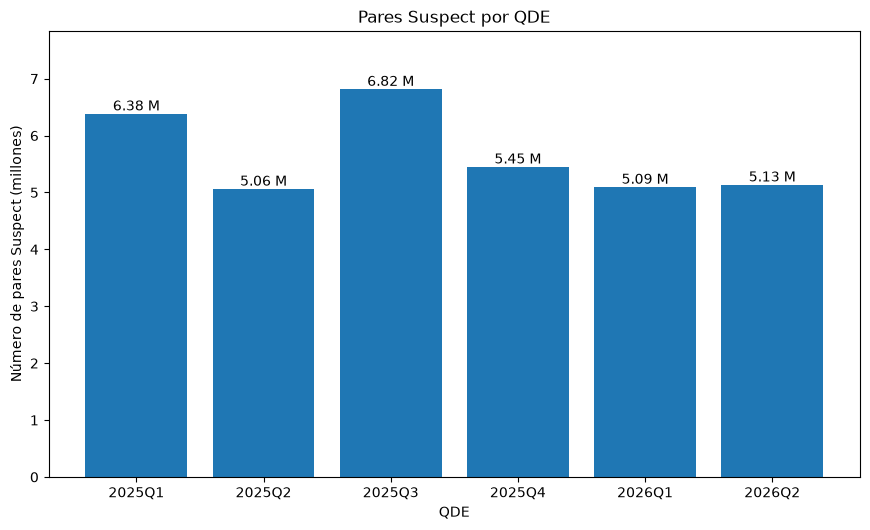

In [7]:

# 1. Cargar el manifiesto de pares (EXTRACTION_DIR y FIGURE_DIR ya existen en tu notebook)
ruta_pares = "derived/extraction_03/pairs_suspect_manifest.csv"
df_pairs = pd.read_csv(ruta_pares)

# 2. Sumar los tres XML de cada trimestre
pairs_qde = (
    df_pairs
    .groupby("qde_period", as_index=False)
    .agg(n_pairs_written=("n_pairs_written", "sum"),
         n_reports_suspect=("n_reports_suspect", "sum"))
    .sort_values("qde_period")
    .reset_index(drop=True)
)
pairs_qde["pairs_millions"] = pairs_qde["n_pairs_written"] / 1_000_000
pairs_qde["pairs_per_report"] = pairs_qde["n_pairs_written"] / pairs_qde["n_reports_suspect"]

print(pairs_qde)
print("Total:", f"{pairs_qde['n_pairs_written'].sum():,}")

# 3. Gráfica de barras
fig, ax = plt.subplots(figsize=(8.8, 5.4))

ax.bar(pairs_qde["qde_period"], pairs_qde["pairs_millions"])

ax.set_title("Pares Suspect por QDE")
ax.set_xlabel("QDE")
ax.set_ylabel("Número de pares Suspect (millones)")

for i, valor in enumerate(pairs_qde["pairs_millions"]):
    ax.text(i, valor, f"{valor:.2f} M", ha="center", va="bottom")

ax.set_ylim(0, pairs_qde["pairs_millions"].max() * 1.15)

fig.tight_layout()
ruta_figura = FIGURE_DIR / "09_pares_suspect_por_qde.png"
fig.savefig(ruta_figura, dpi=300, bbox_inches="tight")
plt.show()



Contesta:
a) ¿qué QDE tiene el mayor número de pares `Suspect`?  

2025Q3 con  6,815,484

b) ¿qué QDE tiene el menor?

2025Q2 con 5,060,969

c) ¿el número de pares sigue necesariamente el mismo patrón que el número de reportes?
Explica:

No necesariamente, los dos coinciden en el extremos alto: 2025Q3 tiene as reportes y mas pares, pero el resto del orden cambia, el mas claro es 2025Q4 que es el trimestre con menor reportes y sin embargo es el tercero en pares, 2026Q2 hace lo contrario, es el segundo en reportes pero solo el cuarto en pares. La razon es que los pares no se generan por reporte sino por producto, cada reporte aporta medicamentos suspect X reacciones, por eso el numero de pared depende de cuantos medicamentos y reacciones tare cada reporte en promedio, no solo de cuantos reportes hay.  


### 10. Disponibilidad geográfica

Carga:

```text
derived/extraction_03/geographic_completeness_by_qde.csv
```

y construye una nueva variable:

$$
N_{\mathrm{known}}
=
N_{\mathrm{reports}}
-
N_{\mathrm{occurcountry\ missing}}.
$$

Después realiza una gráfica de barras apiladas donde, para cada QDE, se muestren:

- reportes con `occurcountry` disponible;
- reportes con `occurcountry` faltante.

Guarda la figura como PNG a 300 dpi.

Finalmente responde:

a) ¿en qué QDE se observa la mayor proporción de `occurcountry` faltante?

b) compara 2025Q1 con 2026Q2;

c) ¿por qué este cambio debe considerarse antes de comparar señales geográficas entre
trimestres?



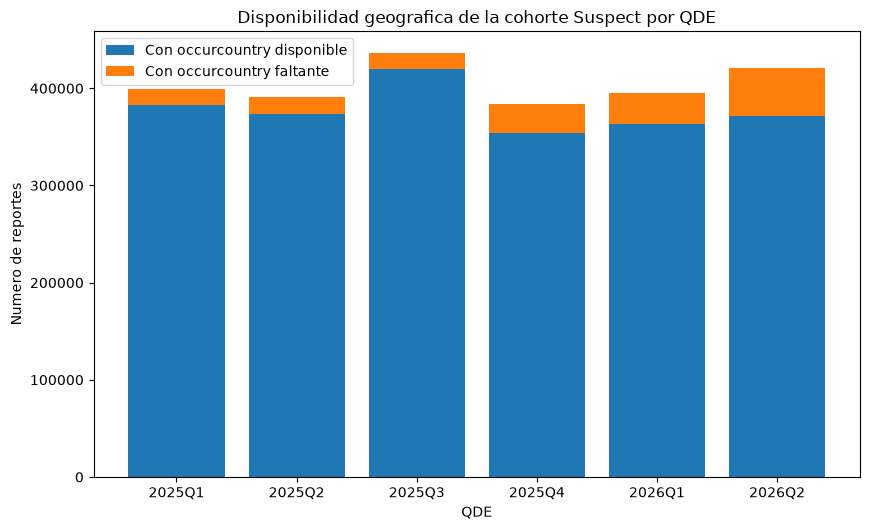

In [15]:
# cargar el archivo de completitud geografica
ruta_geo = "derived/extraction_03/geographic_completeness_by_qde.csv"
df_geo = pd.read_csv(ruta_geo)

# Construir la variable de reportes con pais conocido (occurcountry disponible)
df_geo["n_known"] = df_geo["n_reports"] - df_geo["n_occurcountry_missing"]
fig, ax = plt.subplots(figsize=(8.8, 5.4))
ax.bar(df_geo["qde_period"], df_geo["n_known"], label="Con occurcountry disponible")
ax.bar(df_geo["qde_period"], df_geo["n_occurcountry_missing"], bottom=df_geo["n_known"], label="Con occurcountry faltante")
ax.set_title("Disponibilidad geografica de la cohorte Suspect por QDE")
ax.set_xlabel("QDE")
ax.set_ylabel("Numero de reportes")
ax.legend()
fig.tight_layout()
ruta_figura = FIGURE_DIR / "geographic_bar_chart.png"
fig.savefig(ruta_figura, dpi=300, bbox_inches="tight")
plt.show()

Finalmente responde:

a) ¿en qué QDE se observa la mayor proporción de `occurcountry` faltante?

Usando la informacion obtenida en 16.10 tenemos que el reporte 2026Q2 con 11.61 (48827 de 420481 reportes). Es el trimestre con mas reportes de faltantes. 

b) compara 2025Q1 con 2026Q2  

La proporcion de faltante paso de 4.04% a 11.61% es decir 3 veces mas. En numeros absolutos los faltante subieron de 16113 a 48827, miestras que los reportes solo aumentaron 5.4%. Por eso el aumento de faltantes no se explica por un trimestre mas grande, la completitud geografica empeoro.

c) ¿por qué este cambio debe considerarse antes de comparar señales geográficas entre
trimestres?  
Porque el analisis geografico usa occurcountry como variable principal y los reportes sin ese campo no pueden asignarse a ningun pais. Si la proporcion de fatantes cambia de 4% a 12% cada trimestre cubre una fraccion distinta de sus reportes. Una diferencia entre trimestre en el numero  o la proporcion d pares de un pais o simplemente que en este trimestre hay mas reportes sin pais. 


## Parte C. Análisis propio

### 11. Países con mayor número de reportes

Carga:

```text
derived/extraction_03/occurcountry_frequency.csv
```

y selecciona los 10 valores de `occurcountry` con mayor número de reportes.

Construye una gráfica de barras horizontal ordenada de mayor a menor.




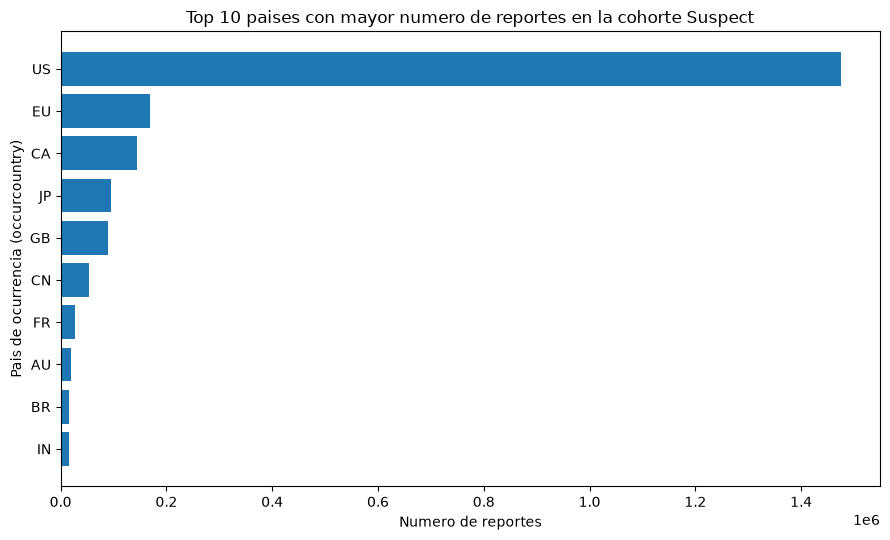

In [65]:

# cargar el archivo de frecuencias de paises
ruta_paises = "derived/extraction_03/occurcountry_frequency.csv"
df_paises = pd.read_csv(ruta_paises)
# seleccionar los 10 valores con mayor numero de reportes
top_10_paises = df_paises.head(10).sort_values("n_reports", ascending=True)
fig, ax = plt.subplots(figsize=(9.0, 5.5))
ax.barh(top_10_paises["occurcountry"], top_10_paises["n_reports"])
ax.set_title("Top 10 paises con mayor numero de reportes en la cohorte Suspect")
ax.set_xlabel("Numero de reportes")
ax.set_ylabel("Pais de ocurrencia (occurcountry)")
fig.tight_layout()
ruta_figura = "derived/extraction_03/figures/top_10_countries.png"
plt.show()

Contesta: 

a) ¿qué porcentaje de los reportes con país conocido corresponde a `US`?
 EL 65.08% (de acuerdo a la seccion 16.11) proviene de Estados Unidos, ya que es el pais que mas aporta notificaciones de FAERS
 
b) ¿qué representa el código `EU` y por qué no debe interpretarse como un país
individual?  
Representa una categoria reginal utilizada cuando los reportes agrupan notificaciones a nivel comiunitario por lo que no debe interpretarse como un pais individual para evitar duplicidades o mezclar estadisticas nacionales en el analisis geografico

c) ¿consideras adecuada una comparación directa de números absolutos de reportes entre
países? Explica qué limitaciones tendría.  
Comparar unicamente numeros absolutos tiene series limitaciones porque no toma en cuenta el tama;o de la poblacion de cada pais, el consumo real de los medicamentos ni las diferencias en la cultura de notificacion o farmacovigilancia de cada sistema de salud. Pais con mas reporte no necesariamente significa que el farmaco sea mas peligroso ahi, sino que simplemente notifica con mucha frecuencia o intensidad

### 12. Reflexión final

En un texto de entre **150 y 250 palabras**, explica con tus propias palabras el
proceso que permitió pasar de los archivos XML originales de FAERS a los

$$
33{,}938{,}903
$$

pares medicamento--reacción de la cohorte `Suspect`.

El texto debe mencionar, por lo menos:

- repetición de registros;
- construcción de `drug_key`;
- `drugcharacterization`;
- selección de la cohorte `Suspect`;
- versionado mediante `release_view`;
- producto cartesiano medicamento--reacción;
- diferencia entre asociación de co-reporte y causalidad;
- información temporal y geográfica.

No se busca repetir literalmente el notebook, sino explicar la lógica del proceso y
justificar las principales decisiones metodológicas.

Para transformar los archivos XML originales de FAERS en la matriz de 33,938,903 pares de medicamento-reaccion de la cohorte Suspect.
En primer lugar, se abordo la repeticion de registros propia de la estructura XML mediante una deduplicacion que eliminó redundancias y ruidos administrativos. Para identificar los farmacos de forma robusta, se realizo la construcción de drug_key, priorizando el ingrediente activo y recurriendo al nombre comercial como respaldo cuando este no estaba disponible.
Posteriormente, mediante el uso de la variable drugcharacterization, se ejecuto la selección de la cohorte Suspect, aislando unicamente los medicamentos señalados como sospechosos. A nivel de cada reporte, se aplico un producto cartesiano medicamento-reaccipn, relacionando cada farmaco con sus eventos adversos correspondientes, paraa dotar de contexto a los datos, se incorporo el versionado mediante release_view, lo que permitió integrar la informacion temporal y geografica esencial, como los trimestres de liberación y recepción, el país de ocurrencia y la seriedad del cuadro clínico.

[Notebook que se utilizo](03_extraccion_medicamentos_reacciones_FAERS.ipynb)